## Import libraries and locate data

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

movies = pd.read_csv(DATA_DIR / "movies.csv")
ratings = pd.read_csv(DATA_DIR / "ratings.csv")
tags = pd.read_csv(DATA_DIR / "tags.csv")
links = pd.read_csv(DATA_DIR / "links.csv")

print("Dataset loaded successfully!")
print("Project folder:", PROJECT_ROOT)

Dataset loaded successfully!
Project folder: c:\Users\night\OneDrive\Desktop\Projects\Hybrid Recommendation System


## Check dataset sizes

In [2]:
print("Movies:", movies.shape)
print("Ratings:", ratings.shape)
print("Tags:", tags.shape)
print("Links:", links.shape)

Movies: (9742, 3)
Ratings: (100836, 4)
Tags: (3683, 4)
Links: (9742, 3)


## View sample data

In [3]:
print("MOVIES")
display(movies.head())

print("RATINGS")
display(ratings.head())

print("TAGS")
display(tags.head())

print("LINKS")
display(links.head())

MOVIES


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


RATINGS


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


TAGS


,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200


LINKS


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0
3,4,114885,31357.0
4,5,113041,11862.0


## Basic statistics

In [4]:
print("Total ratings:", len(ratings))
print("Unique users:", ratings["userId"].nunique())
print("Unique rated movies:", ratings["movieId"].nunique())
print("Unique movies in movies.csv:", movies["movieId"].nunique())

print("\nRating statistics:")
display(ratings["rating"].describe())

Total ratings: 100836
Unique users: 610
Unique rated movies: 9724
Unique movies in movies.csv: 9742

Rating statistics:


count    100836.000000
mean          3.501557
std           1.042529
min           0.500000
25%           3.000000
50%           3.500000
75%           4.000000
max           5.000000
Name: rating, dtype: float64

## Check missing values

In [5]:
print("Missing values in movies:")
display(movies.isnull().sum())

print("Missing values in ratings:")
display(ratings.isnull().sum())

print("Missing values in tags:")
display(tags.isnull().sum())

print("Missing values in links:")
display(links.isnull().sum())

Missing values in movies:


movieId    0
title      0
genres     0
dtype: int64

Missing values in ratings:


userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Missing values in tags:


userId       0
movieId      0
tag          0
timestamp    0
dtype: int64

Missing values in links:


movieId    0
imdbId     0
tmdbId     8
dtype: int64

## Check duplicate rows

In [6]:
print("Duplicate movie rows:", movies.duplicated().sum())
print("Duplicate rating rows:", ratings.duplicated().sum())
print("Duplicate tag rows:", tags.duplicated().sum())
print("Duplicate link rows:", links.duplicated().sum())

Duplicate movie rows: 0
Duplicate rating rows: 0
Duplicate tag rows: 0
Duplicate link rows: 0


## Find the most-rated movies

In [ ]:
movie_counts = (
    ratings.groupby("movieId")
    .size()
    .reset_index(name="rating_count")
)

popular_movies = movie_counts.merge(
    movies[["movieId", "title"]],
    on="movieId",
    how="left"
)

popular_movies = popular_movies.sort_values(
    "rating_count",
    ascending=False
)

display(popular_movies.head(10))

,movieId,rating_count,title
314,356,329,Forrest Gump (1994)
277,318,317,"Shawshank Redemption, The (1994)"
257,296,307,Pulp Fiction (1994)
510,593,279,"Silence of the Lambs, The (1991)"
1938,2571,278,"Matrix, The (1999)"
224,260,251,Star Wars: Episode IV - A New Hope (1977)
418,480,238,Jurassic Park (1993)
97,110,237,Braveheart (1995)
507,589,224,Terminator 2: Judgment Day (1991)
461,527,220,Schindler's List (1993)


## Explore the distribution of ratings

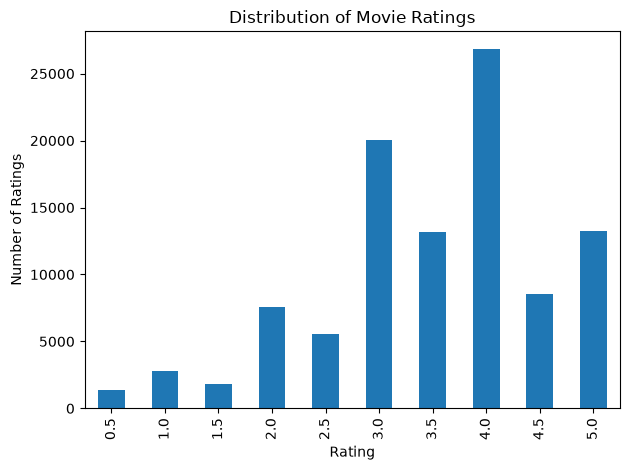

In [8]:
ratings["rating"].value_counts().sort_index().plot(
    kind="bar",
    title="Distribution of Movie Ratings",
    xlabel="Rating",
    ylabel="Number of Ratings"
)

plt.tight_layout()
plt.show()

## Explore movie genres

,movie_count
genre_list,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


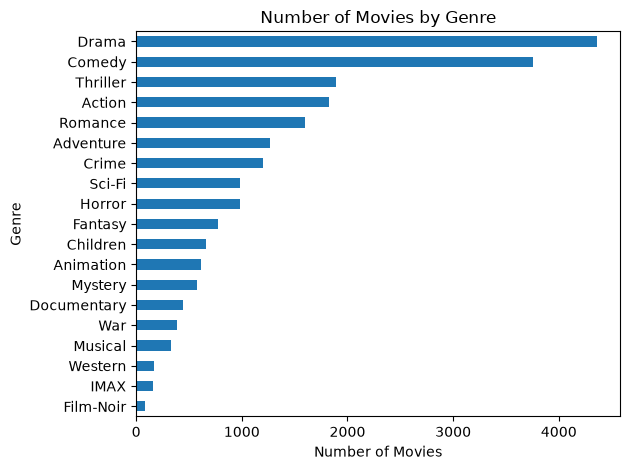

In [9]:
movies["genre_list"] = movies["genres"].apply(
    lambda x: x.split("|")
    if isinstance(x, str) and x != "(no genres listed)"
    else []
)

genre_counts = (
    movies.explode("genre_list")["genre_list"]
    .value_counts()
)

display(genre_counts.to_frame(name="movie_count"))

genre_counts.sort_values().plot(
    kind="barh",
    title="Number of Movies by Genre",
    xlabel="Number of Movies",
    ylabel="Genre"
)

plt.tight_layout()
plt.show()

## Data Exploration Conclusion

- The dataset contains movie details and user ratings.
- The ratings data helps us understand user preferences.
- Genre information can be used for content-based recommendations.
- Rating counts help us build a popularity-based baseline.
- The dataset will be used to develop and evaluate recommendation models.